# BRFSS 2025: Diabetes, Income, Age and Lifestyle

Cleaning and analysis notebook. Raw data: CDC BRFSS 2025 (LLCP2025.XPT).

Steps: load the data, turn survey codes (7, 9, 77, 99) into missing values, check that row counts add up, then compare diabetes rates by income, age, BMI, exercise and smoking.

Note: file paths assume the notebook sits one level above the `brfss-health-project` folder.

In [2]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\HP\Documents
['.ipynb_checkpoints', '01_cleaning', 'brfss-health-project', 'desktop.ini', 'My Music', 'My Pictures', 'My Videos']


In [6]:
import pandas as pd

df = pd.read_sas("brfss-health-project/data/LLCP2025XPT/LLCP2025.XPT", format="xport")
print(df.shape)

(356158, 283)


In [7]:
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [8]:
print(list(df.columns[:40]))


['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX4', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX4', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'BPHIGH6', 'BPMEDS1']


In [10]:
cols = ["_STATE", "SEXVAR", "_AGEG5YR", "INCOME3", "_BMI5",
        "SMOKE100", "EXERANY2", "GENHLTH", "DIABETE4", "CVDCRHD4", "CVDINFR4"]

small = df[cols].copy()
print(small.shape)
small.head()

(356158, 11)


,_STATE,SEXVAR,_AGEG5YR,INCOME3,_BMI5,SMOKE100,EXERANY2,GENHLTH,DIABETE4,CVDCRHD4,CVDINFR4
0,1.0,2.0,11.0,6.0,3079.0,2.0,1.0,3.0,3.0,2.0,2.0
1,1.0,2.0,13.0,77.0,1966.0,2.0,1.0,3.0,1.0,2.0,2.0
2,1.0,2.0,10.0,77.0,3320.0,2.0,2.0,4.0,1.0,2.0,2.0
3,1.0,1.0,13.0,77.0,2980.0,2.0,2.0,4.0,1.0,2.0,2.0
4,1.0,1.0,9.0,7.0,2846.0,2.0,1.0,3.0,3.0,2.0,2.0


In [11]:
small.to_csv("brfss-health-project/data/brfss_small.csv", index=False)

In [12]:
small["DIABETE4"].value_counts()

DIABETE4
3.0    290712
1.0     51827
4.0     10166
2.0      2671
7.0       580
9.0       196
Name: count, dtype: int64

In [14]:
diabetes_labels = {
    1.0: "Yes",
    2.0: "Pregnancy only",
    3.0: "No",
    4.0: "Pre-diabetes",
}

small["diabetes"] = small["DIABETE4"].map(diabetes_labels)

print(small["diabetes"].value_counts(dropna=False))

diabetes
No                290712
Yes                51827
Pre-diabetes       10166
Pregnancy only      2671
NaN                  782
Name: count, dtype: int64


In [15]:
print(small["CVDCRHD4"].value_counts(dropna=False))
print(small["CVDINFR4"].value_counts(dropna=False))

CVDCRHD4
2.0    331782
1.0     20700
7.0      3471
9.0       202
NaN         3
Name: count, dtype: int64
CVDINFR4
2.0    333818
1.0     20106
7.0      2050
9.0       181
NaN         3
Name: count, dtype: int64


In [16]:
yes_no = {1.0: "Yes", 2.0: "No"}

small["heart_disease"] = small["CVDCRHD4"].map(yes_no)
small["heart_attack"] = small["CVDINFR4"].map(yes_no)

print(small["heart_disease"].value_counts(dropna=False))
print(small["heart_attack"].value_counts(dropna=False))

heart_disease
No     331782
Yes     20700
NaN      3676
Name: count, dtype: int64
heart_attack
No     333818
Yes     20106
NaN      2234
Name: count, dtype: int64


In [17]:
for c in ["SEXVAR", "SMOKE100", "EXERANY2", "GENHLTH"]:
    print(small[c].value_counts(dropna=False).sort_index())
    print()

SEXVAR
1.0    168462
2.0    187696
Name: count, dtype: int64

SMOKE100
1.0    130943
2.0    204951
7.0      1513
9.0       497
NaN     18254
Name: count, dtype: int64

EXERANY2
1.0    272901
2.0     82283
7.0       653
9.0       319
NaN         2
Name: count, dtype: int64

GENHLTH
1.0     48860
2.0    114578
3.0    120795
4.0     53372
5.0     17589
7.0       685
9.0       274
NaN         5
Name: count, dtype: int64



In [18]:
small["sex"] = small["SEXVAR"].map({1.0: "Male", 2.0: "Female"})
small["smoked_100"] = small["SMOKE100"].map(yes_no)
small["exercise"] = small["EXERANY2"].map(yes_no)

health_labels = {1.0: "Excellent", 2.0: "Very good", 3.0: "Good", 4.0: "Fair", 5.0: "Poor"}
small["general_health"] = small["GENHLTH"].map(health_labels)

for c in ["sex", "smoked_100", "exercise", "general_health"]:
    print(small[c].value_counts(dropna=False))
    print()

sex
Female    187696
Male      168462
Name: count, dtype: int64

smoked_100
No     204951
Yes    130943
NaN     20264
Name: count, dtype: int64

exercise
Yes    272901
No      82283
NaN       974
Name: count, dtype: int64

general_health
Good         120795
Very good    114578
Fair          53372
Excellent     48860
Poor          17589
NaN             964
Name: count, dtype: int64



In [19]:
print(small["_BMI5"].describe())
print()
print(small["_AGEG5YR"].value_counts(dropna=False).sort_index())
print()
print(small["INCOME3"].value_counts(dropna=False).sort_index())

count    323596.000000
mean       2847.264790
std         653.000027
min        1202.000000
25%        2407.000000
50%        2741.000000
75%        3162.000000
max        9843.000000
Name: _BMI5, dtype: float64

_AGEG5YR
1.0     23236
2.0     18003
3.0     19325
4.0     21444
5.0     22985
6.0     22020
7.0     23134
8.0     26007
9.0     32586
10.0    37109
11.0    35682
12.0    31071
13.0    36874
14.0     6682
Name: count, dtype: int64

INCOME3
1.0      7723
2.0      7971
3.0     10285
4.0     15257
5.0     31691
6.0     37977
7.0     46329
8.0     39932
9.0     43403
10.0    21174
11.0    23366
77.0    29831
99.0    34081
NaN      7138
Name: count, dtype: int64


In [20]:
# BMI: move the decimal point two places
small["bmi"] = small["_BMI5"] / 100

# Age: translate codes to labels, 14 becomes missing automatically
age_labels = {
    1.0: "18-24", 2.0: "25-29", 3.0: "30-34", 4.0: "35-39",
    5.0: "40-44", 6.0: "45-49", 7.0: "50-54", 8.0: "55-59",
    9.0: "60-64", 10.0: "65-69", 11.0: "70-74", 12.0: "75-79",
    13.0: "80+",
}
small["age_group"] = small["_AGEG5YR"].map(age_labels)

# Income: translate codes to labels, 77 and 99 become missing automatically
income_labels = {
    1.0: "<$10k", 2.0: "$10-15k", 3.0: "$15-20k", 4.0: "$20-25k",
    5.0: "$25-35k", 6.0: "$35-50k", 7.0: "$50-75k", 8.0: "$75-100k",
    9.0: "$100-150k", 10.0: "$150-200k", 11.0: "$200k+",
}
small["income"] = small["INCOME3"].map(income_labels)

print(small["bmi"].describe())
print(small["age_group"].value_counts(dropna=False))
print(small["income"].value_counts(dropna=False))

count    323596.000000
mean         28.472648
std           6.530000
min          12.020000
25%          24.070000
50%          27.410000
75%          31.620000
max          98.430000
Name: bmi, dtype: float64
age_group
65-69    37109
80+      36874
70-74    35682
60-64    32586
75-79    31071
55-59    26007
18-24    23236
50-54    23134
40-44    22985
45-49    22020
35-39    21444
30-34    19325
25-29    18003
NaN       6682
Name: count, dtype: int64
income
NaN          71050
$50-75k      46329
$100-150k    43403
$75-100k     39932
$35-50k      37977
$25-35k      31691
$200k+       23366
$150-200k    21174
$20-25k      15257
$15-20k      10285
$10-15k       7971
<$10k         7723
Name: count, dtype: int64


In [21]:
clean = small[["_STATE", "sex", "age_group", "income", "bmi",
               "smoked_100", "exercise", "general_health",
               "diabetes", "heart_disease", "heart_attack"]].copy()

clean = clean.rename(columns={"_STATE": "state"})

print(clean.shape)
clean.head()

(356158, 11)


,state,sex,age_group,income,bmi,smoked_100,exercise,general_health,diabetes,heart_disease,heart_attack
0,1.0,Female,70-74,$35-50k,30.79,No,Yes,Good,No,No,No
1,1.0,Female,80+,NaN,19.66,No,Yes,Good,Yes,No,No
2,1.0,Female,65-69,NaN,33.20,No,No,Fair,Yes,No,No
3,1.0,Male,80+,NaN,29.80,No,No,Fair,Yes,No,No
4,1.0,Male,60-64,$50-75k,28.46,No,Yes,Good,No,No,No


In [22]:
clean.to_csv("brfss-health-project/data/brfss_clean.csv", index=False)

print((clean.isna().mean() * 100).round(1))

state              0.0
sex                0.0
age_group          1.9
income            19.9
bmi                9.1
smoked_100         5.7
exercise           0.3
general_health     0.3
diabetes           0.2
heart_disease      1.0
heart_attack       0.6
dtype: float64


In [23]:
# 1 = has diabetes, 0 = doesn't, missing stays missing
clean["has_diabetes"] = (clean["diabetes"] == "Yes").astype(float)
clean.loc[clean["diabetes"].isna(), "has_diabetes"] = float("nan")

print(clean["has_diabetes"].value_counts(dropna=False))

has_diabetes
0.0    303549
1.0     51827
NaN       782
Name: count, dtype: int64


In [24]:
income_order = ["<$10k", "$10-15k", "$15-20k", "$20-25k", "$25-35k",
                "$35-50k", "$50-75k", "$75-100k", "$100-150k", "$150-200k", "$200k+"]

by_income = (clean.groupby("income")["has_diabetes"]
             .mean()
             .mul(100)
             .round(1)
             .reindex(income_order))

print(by_income)

income
<$10k        18.9
$10-15k      25.4
$15-20k      23.4
$20-25k      23.0
$25-35k      19.0
$35-50k      16.8
$50-75k      14.7
$75-100k     12.7
$100-150k    10.7
$150-200k     8.6
$200k+        6.4
Name: has_diabetes, dtype: float64


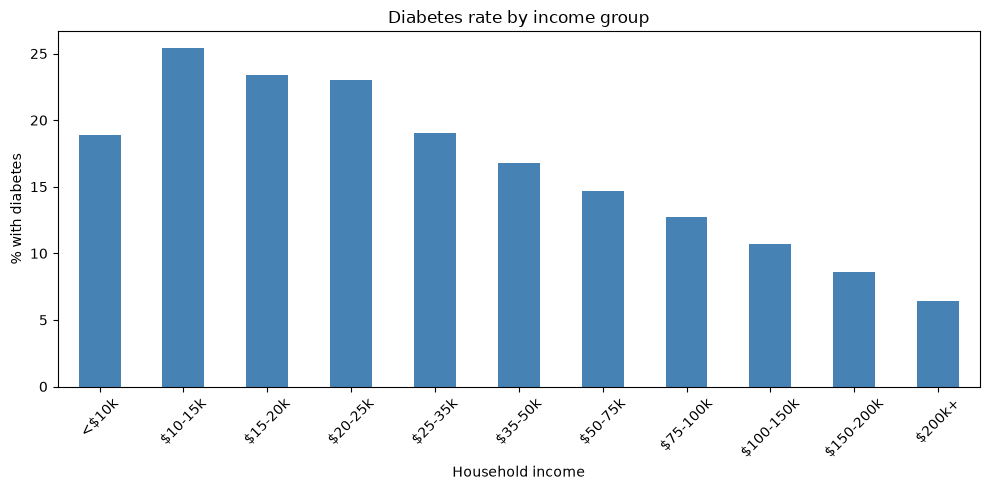

In [25]:
import matplotlib.pyplot as plt

by_income.plot(kind="bar", figsize=(10, 5), color="steelblue")
plt.title("Diabetes rate by income group")
plt.ylabel("% with diabetes")
plt.xlabel("Household income")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
young = ["18-24", "25-29", "30-34", "35-39", "40-44"]
middle = ["45-49", "50-54", "55-59", "60-64"]
older = ["65-69", "70-74", "75-79", "80+"]

band_map = {a: "18-44" for a in young}
band_map.update({a: "45-64" for a in middle})
band_map.update({a: "65+" for a in older})

clean["age_band"] = clean["age_group"].map(band_map)
print(clean["age_band"].value_counts(dropna=False))

age_band
65+      140736
18-44    104993
45-64    103747
NaN        6682
Name: count, dtype: int64


In [27]:
pivot = (clean.pivot_table(index="income", columns="age_band",
                           values="has_diabetes", aggfunc="mean")
         .mul(100).round(1)
         .reindex(income_order)[["18-44", "45-64", "65+"]])

print(pivot)

age_band   18-44  45-64   65+
income                       
<$10k        7.1   25.4  30.5
$10-15k      7.5   30.5  30.6
$15-20k      6.8   27.9  29.9
$20-25k      5.7   26.7  29.9
$25-35k      5.1   22.3  25.7
$35-50k      4.1   19.6  23.3
$50-75k      3.4   16.5  21.3
$75-100k     2.9   14.2  19.4
$100-150k    2.7   12.4  17.4
$150-200k    2.3   10.5  14.9
$200k+       1.8    7.5  11.9


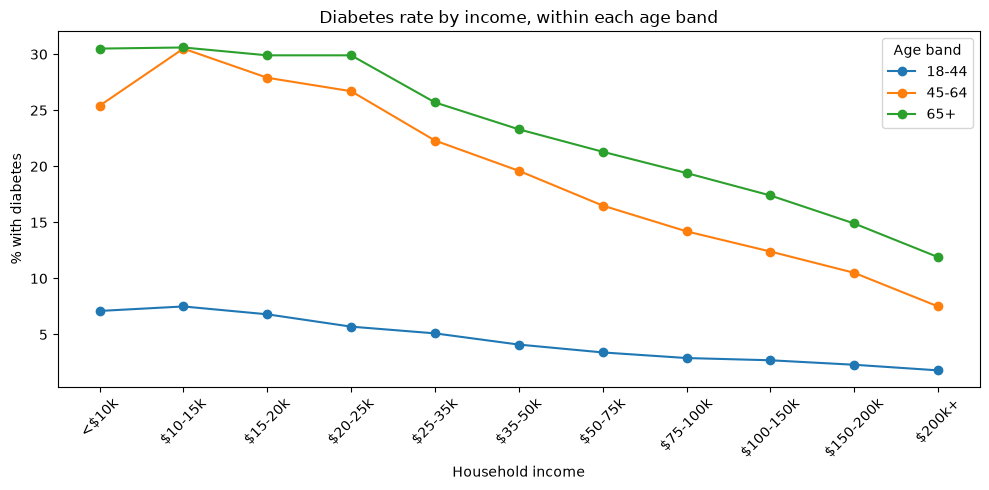

In [28]:
pivot.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Diabetes rate by income, within each age band")
plt.ylabel("% with diabetes")
plt.xlabel("Household income")
plt.xticks(range(len(income_order)), income_order, rotation=45)
plt.legend(title="Age band")
plt.tight_layout()
plt.savefig("brfss-health-project/diabetes_by_income_age.png", dpi=150)
plt.show()

In [29]:
import sqlite3

conn = sqlite3.connect("brfss-health-project/data/brfss.db")
clean.to_sql("brfss", conn, if_exists="replace", index=False)

print("Saved", len(clean), "rows")

Saved 356158 rows


In [30]:
query = """
SELECT income,
       ROUND(100.0 * AVG(CASE WHEN diabetes = 'Yes' THEN 1.0 ELSE 0 END), 1) AS diabetes_pct,
       COUNT(*) AS people
FROM brfss
WHERE income IS NOT NULL AND diabetes IS NOT NULL
GROUP BY income
ORDER BY diabetes_pct DESC
"""

pd.read_sql(query, conn)

,income,diabetes_pct,people
0,$10-15k,25.4,7947
1,$15-20k,23.4,10257
2,$20-25k,23.0,15223
3,$25-35k,19.0,31624
4,<$10k,18.9,7685
5,$35-50k,16.8,37929
6,$50-75k,14.7,46279
7,$75-100k,12.7,39901
8,$100-150k,10.7,43378
9,$150-200k,8.6,21162


In [31]:
for col in ["exercise", "smoked_100"]:
    print(clean.groupby(col)["has_diabetes"].mean().mul(100).round(1))
    print()

exercise
No     23.8
Yes    11.8
Name: has_diabetes, dtype: float64

smoked_100
No     13.0
Yes    17.4
Name: has_diabetes, dtype: float64



In [32]:
clean["bmi_group"] = pd.cut(
    clean["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
)

print(clean["bmi_group"].value_counts(dropna=False))
print()
print(clean.groupby("bmi_group", observed=False)["has_diabetes"].mean().mul(100).round(1))

bmi_group
Overweight     114838
Obese          106934
Normal          96272
NaN             32562
Underweight      5552
Name: count, dtype: int64

bmi_group
Underweight     6.1
Normal          7.9
Overweight     13.6
Obese          22.6
Name: has_diabetes, dtype: float64


In [33]:
for col in ["exercise", "bmi_group"]:
    table = (clean.pivot_table(index=col, columns="age_band",
                               values="has_diabetes", aggfunc="mean",
                               observed=False)
             .mul(100).round(1)[["18-44", "45-64", "65+"]])
    print(table)
    print()

age_band  18-44  45-64   65+
exercise                    
No          5.9   25.8  30.8
Yes         3.1   13.1  18.4

age_band     18-44  45-64   65+
bmi_group                      
Underweight    0.9    8.0   9.6
Normal         1.4    7.8  13.1
Overweight     2.4   12.9  21.0
Obese          7.3   24.4  32.7



In [34]:
clean.to_csv("brfss-health-project/data/brfss_clean.csv", index=False)

import os
size_mb = os.path.getsize("brfss-health-project/data/brfss_clean.csv") / 1e6
print(round(size_mb, 1), "MB")

25.1 MB


In [35]:
clean.to_csv("brfss-health-project/data/brfss_clean.csv.gz", index=False, compression="gzip")

size_mb = os.path.getsize("brfss-health-project/data/brfss_clean.csv.gz") / 1e6
print(round(size_mb, 1), "MB")

2.8 MB


In [36]:
test = pd.read_csv("brfss-health-project/data/brfss_clean.csv.gz")
print(test.shape)
print(clean.shape)

(356158, 14)
(356158, 14)


In [37]:
import streamlit
print(streamlit.__version__)

1.58.0


In [45]:
%%writefile brfss-health-project/app/app.py
import pandas as pd
import streamlit as st

st.title("Diabetes and Income: BRFSS 2025")
st.caption("Survey sample rates, not weighted to the US population. Shows association, not cause.")

@st.cache_data
def load_data():
    return pd.read_csv("data/brfss_clean.csv.gz")

df = load_data()

income_order = ["<$10k", "$10-15k", "$15-20k", "$20-25k", "$25-35k",
                "$35-50k", "$50-75k", "$75-100k", "$100-150k", "$150-200k", "$200k+"]

# Filters in the sidebar
age_choice = st.sidebar.selectbox("Age band", ["All", "18-44", "45-64", "65+"])
sex_choice = st.sidebar.selectbox("Sex", ["All", "Female", "Male"])

filtered = df.copy()
if age_choice != "All":
    filtered = filtered[filtered["age_band"] == age_choice]
if sex_choice != "All":
    filtered = filtered[filtered["sex"] == sex_choice]

st.write("People in this view:", len(filtered))

# Diabetes rate by income
rates = (filtered.groupby("income")["has_diabetes"]
         .mean().mul(100).round(1)
         .reindex(income_order))

st.subheader("Diabetes rate by income")
st.bar_chart(rates)
st.caption("Percent of people with diabetes in each income group.")

Overwriting brfss-health-project/app/app.py
